In [1]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Выбор датасета и постановка задачи

### Ссылка на датасет: https://www.kaggle.com/datasets/safdarjoon/ames-housing

In [7]:
df = pd.read_csv('../laba 4/AmesHousing.csv')

rows, cols = df.shape
print(f"Количество строк: {rows}")
print(f"Количество столбцов: {cols}")
print(f"Типы данных:")
print(df.dtypes.value_counts())
df.head()

Количество строк: 2752
Количество столбцов: 251
Типы данных:
float64    247
int64        4
Name: count, dtype: int64


,Lot_Frontage,Overall_Qual,Overall_Cond,Exter_Qual,Exter_Cond,Bsmt_Qual,Bsmt_Cond,Bsmt_Exposure,BsmtFin_Type_1,BsmtFin_SF_1,...,Open_Porch_SF_T,Has_Wood_Deck_SF,Wood_Deck_SF_T,Year_Built,Year_Remod/Add,Yr_Sold,Garage_Yr_Blt,MoSold_sin,Mo_Sold,MoSold_cos
0,0.546984,0.555556,0.500,0.333333,0.333333,0.6,0.8,1.00,0.666667,0.707636,...,0.652731,1.0,0.736975,1960,1960,2010,1960.0,5.000000e-01,5,-8.660254e-01
1,0.323298,0.444444,0.625,0.333333,0.333333,0.6,0.6,0.25,0.500000,0.644969,...,0.000000,1.0,0.681466,1961,1961,2010,1961.0,1.224647e-16,6,-1.000000e+00
2,0.327515,0.555556,0.625,0.333333,0.333333,0.6,0.6,0.25,0.833333,0.787599,...,0.568882,1.0,0.822970,1958,1958,2010,1958.0,1.224647e-16,6,-1.000000e+00
3,0.376337,0.666667,0.500,0.666667,0.333333,0.6,0.6,0.25,0.833333,0.820573,...,0.000000,0.0,0.000000,1968,1968,2010,1968.0,8.660254e-01,4,-5.000000e-01
4,0.297458,0.444444,0.500,0.333333,0.333333,0.8,0.6,0.25,1.000000,0.753221,...,0.560128,1.0,0.738274,1997,1998,2010,1997.0,1.000000e+00,3,6.123234e-17


1. Датасет содержит информацию о жилых домах, проданных в городе Эймс (штат Айова, США) в период с 2006 по 2010 год. 
2. Прикладная задача:
Разработать модель машинного обучения для прогнозирования рыночной стоимости жилого дома на основе его физических характеристик, местоположения и года постройки.
3. Целевая переменная - Log_SalePrice (цена продажи дома). Создатели датасета уже на этапе предобработки применили логарифмирование к исходной цене продажи.
Тип переменной - непрерывная числовая, следовательно тип задачи - регрессия
4. Объём выборки: 2752 объектов. Этого достаточно для уверенного разделения на обучающую (80% ≈ 2201 объекта) и тестовую (20% ≈ 551 объектов) выборки, а также для проведения кросс-валидации.
Количество объектов (строк): 2 752 наблюдения (отдельные объекты недвижимости).
Количество признаков (столбцов): 251 (включая целевую переменную).
Характеристика признаков:
Нормализованные числовые: Lot_Frontage, Overall_Qual, Overall_Cond и др.
Закодированные категориальные: Bsmt_Exposure, BsmtFin_Type_1 и множество бинарных признаков (результат One-Hot Encoding).
Сконструированные (Feature Engineering): MoSold_sin, MoSold_cos (циклическое кодирование месяца продажи для учета сезонности).
Временные: Year_Built, Year_Remod/Add, Yr_Sold.

## 2. Первичный анализ данных и подготовка выборок

Размер: 2752 объектов, 251 признаков

=== Типы данных признаков ===
float64    247
int64        4
Name: count, dtype: int64

Всего пропусков в датасете: 0
Полных дубликатов строк: 0

=== Описательные статистики ===
       Lot_Frontage  Overall_Qual  Overall_Cond  Exter_Qual  Exter_Cond  \
count      2752.000      2752.000      2752.000    2752.000    2752.000   
mean          0.267         0.570         0.572       0.467       0.363   
std           0.091         0.148         0.136       0.188       0.120   
min           0.000         0.000         0.000       0.000       0.000   
25%           0.233         0.444         0.500       0.333       0.333   
50%           0.271         0.556         0.500       0.333       0.333   
75%           0.315         0.667         0.625       0.667       0.333   
max           1.000         1.000         1.000       1.000       1.000   

       Bsmt_Qual  Bsmt_Cond  Bsmt_Exposure  BsmtFin_Type_1  BsmtFin_SF_1  ...  \
count   2752.000   2752.000 

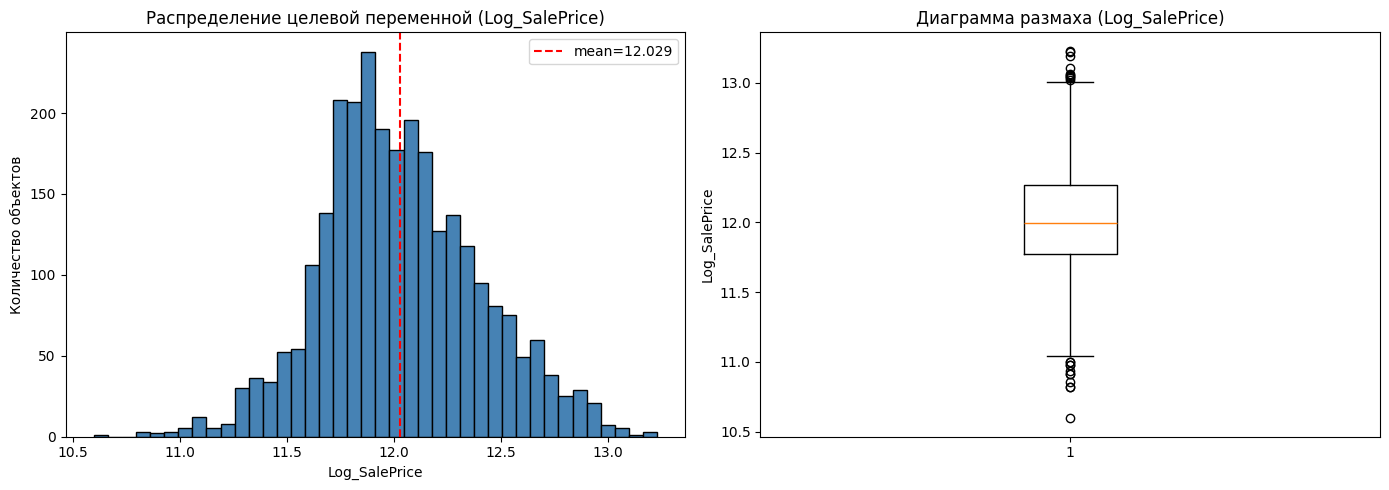

In [17]:
# структура датасета и типов признаков
print(f"Размер: {df.shape[0]} объектов, {df.shape[1]} признаков\n")

print("=== Типы данных признаков ===")
print(df.dtypes.value_counts())

missing_total = df.isnull().sum().sum()
print(f"\nВсего пропусков в датасете: {missing_total}")

duplicates_total = df.duplicated().sum()
print(f"Полных дубликатов строк: {duplicates_total}")

print("\n=== Описательные статистики ===")
print(df.describe().round(3))

# Разделение на X и y
X = df.drop('Log_SalePrice', axis=1)
y = df['Log_SalePrice']

# Разделение на обучающую и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\n=== Размеры выборок ===")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")

print("\n=== Пропуски после разбиения ===")
print(f"X_train: {X_train.isnull().sum().sum()}")
print(f"X_test:  {X_test.isnull().sum().sum()}")
print(f"y_train: {y_train.isnull().sum().sum()}")
print(f"y_test:  {y_test.isnull().sum().sum()}")

# Распределение целевой переменной
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
axes[0].hist(y, bins=40, edgecolor='black', color='steelblue')
axes[0].set_title('Распределение целевой переменной (Log_SalePrice)')
axes[0].set_xlabel('Log_SalePrice')
axes[0].set_ylabel('Количество объектов')
axes[0].axvline(y.mean(), color='red', linestyle='--', label=f'mean={y.mean():.3f}')
axes[0].legend()

# Boxplot для выявления аномалий
axes[1].boxplot(y, vert=True)
axes[1].set_title('Диаграмма размаха (Log_SalePrice)')
axes[1].set_ylabel('Log_SalePrice')

plt.tight_layout()
plt.show()

1. В целевой переменной аномалий нет, а в признаках присутствуют единичные выбросы/ошибки ввода (например, Garage_Yr_Blt = 2207 и 0 как индикатор отсутствия гаража), но для деревьев решений это не критично, поэтому оставили без изменений. Дополнительная предобработка (масштабирование, кодирование) не проводилась, так как датасет уже был предварительно обработан.
2. Целевая переменная: Log_SalePrice — логарифм цены продажи, непрерывная числовая величина. Распределение близко к нормальному (среднее ~12.03, стандартное отклонение ~0.37), явных экстремальных выбросов по boxplot не наблюдается. Это подтверждает, что задача — регрессия.
3. Разбиение выборок: данные разделены в пропорции 80/20 с фиксированным random_state=42. Проверка пропусков в каждой из четырёх частей (X_train, X_test, y_train, y_test) подтвердила их отсутствие, утечка данных исключена, так как разбиение выполнено до каких-либо преобразований.

## 3. Построение и интерпретация базового дерева решений

MSE базового дерева (без ограничений) на трейне: 0.0000
MSE базового дерева (без ограничений) на тесте: 0.0299


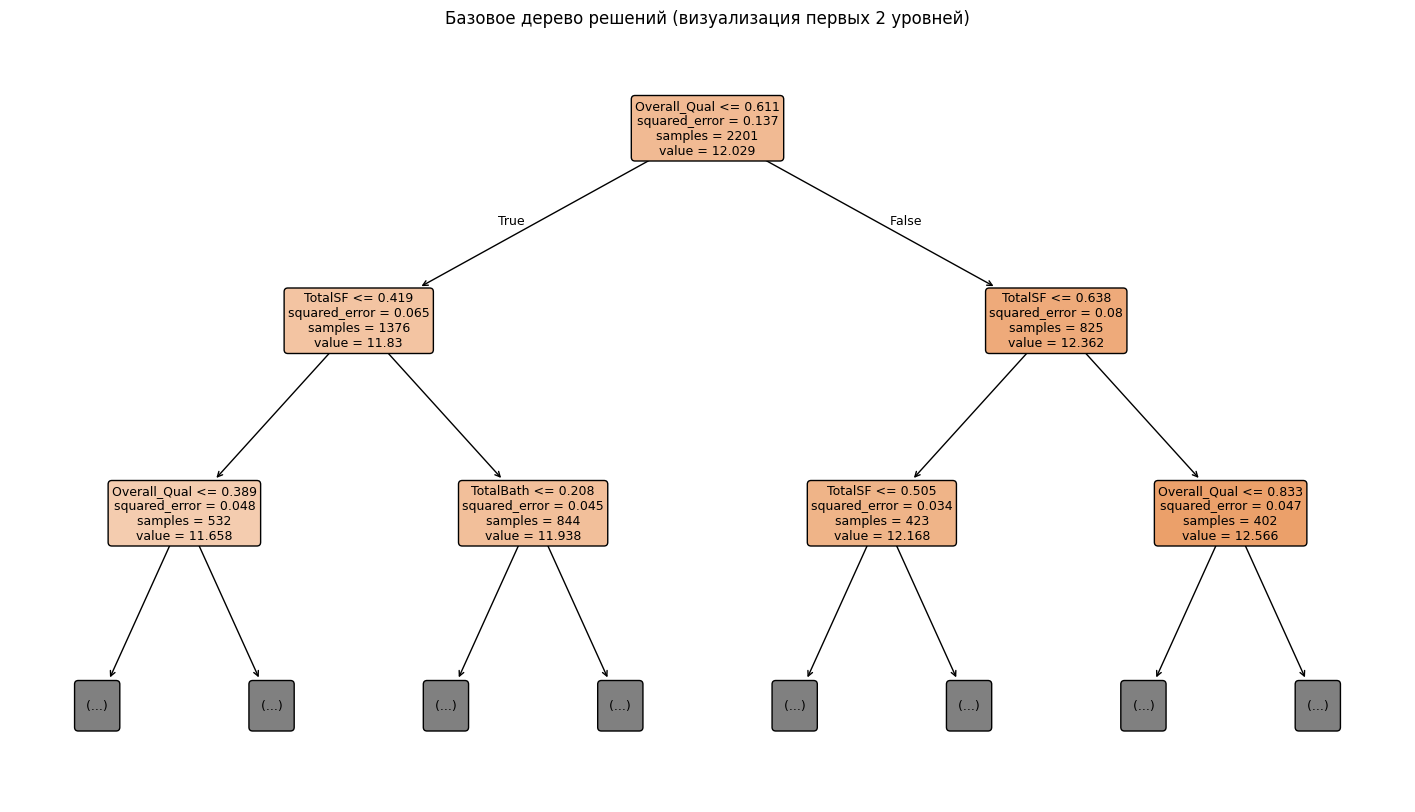

MSE базового дерева на тестовой выборке: 0.0299

=== РУЧНОЙ РАСЧЕТ РАЗБИЕНИЯ ===
Целевые значения (y) фрагмента: [12.5602 11.728  11.976  11.7159 12.5672 12.2405]

1. Родительский узел: Среднее = 12.1313, MSE = 0.1242

2. Разбиение по 'Overall_Qual' <= 0.5556: взвешенная MSE = 0.0307, Gain = 0.0935
3. Разбиение по 'Gr_Liv_Area' <= 0.6358: взвешенная MSE = 0.1018, Gain = 0.0224

4. Алгоритм выберет вариант с большим Gain: Overall_Qual


In [29]:
# Обучение базового дерева
baseline_tree = DecisionTreeRegressor(random_state=42)
baseline_tree.fit(X_train, y_train)

y_pred_base = baseline_tree.predict(X_test)
print(f"MSE базового дерева (без ограничений) на трейне: {mean_squared_error(y_train, baseline_tree.predict(X_train)):.4f}")
print(f"MSE базового дерева (без ограничений) на тесте: {mean_squared_error(y_test, y_pred_base):.4f}")

# Визуализация (ограничиваем глубину для отрисовки, чтобы было читаемо)
plt.figure(figsize=(18, 10))
plot_tree(baseline_tree, feature_names=X.columns, filled=True, rounded=True, fontsize=9, max_depth=2) 
plt.title("Базовое дерево решений (визуализация первых 2 уровней)")
plt.show()

# Оценка на тесте
y_pred_base = baseline_tree.predict(X_test)
mse_test_base = mean_squared_error(y_test, y_pred_base)
print(f"MSE базового дерева на тестовой выборке: {mse_test_base:.4f}")

# Ручной расчет разбиения 
n_samples = 6
X_sample = X_train.iloc[:n_samples].copy()
y_sample = y_train.iloc[:n_samples].values

print("\n=== РУЧНОЙ РАСЧЕТ РАЗБИЕНИЯ ===")
print(f"Целевые значения (y) фрагмента: {np.round(y_sample, 4)}")

parent_mean = np.mean(y_sample)
parent_mse = np.mean((y_sample - parent_mean)**2)
print(f"\n1. Родительский узел: Среднее = {parent_mean:.4f}, MSE = {parent_mse:.4f}")

# Вариант 1: разбиение по Overall_Qual
feat1 = 'Overall_Qual'
thr1 = X_sample[feat1].median()
left1 = y_sample[X_sample[feat1] <= thr1]
right1 = y_sample[X_sample[feat1] > thr1]
w_mse1 = (len(left1)/n_samples)*np.mean((left1-left1.mean())**2) + \
         (len(right1)/n_samples)*np.mean((right1-right1.mean())**2)
gain1 = parent_mse - w_mse1

# Вариант 2: разбиение по Gr_Liv_Area 
feat2 = 'Gr_Liv_Area'
thr2 = X_sample[feat2].median()
left2 = y_sample[X_sample[feat2] <= thr2]
right2 = y_sample[X_sample[feat2] > thr2]
w_mse2 = (len(left2)/n_samples)*np.mean((left2-left2.mean())**2) + \
         (len(right2)/n_samples)*np.mean((right2-right2.mean())**2)
gain2 = parent_mse - w_mse2

print(f"\n2. Разбиение по '{feat1}' <= {thr1:.4f}: взвешенная MSE = {w_mse1:.4f}, Gain = {gain1:.4f}")
print(f"3. Разбиение по '{feat2}' <= {thr2:.4f}: взвешенная MSE = {w_mse2:.4f}, Gain = {gain2:.4f}")
print(f"\n4. Алгоритм выберет вариант с большим Gain: {'Overall_Qual' if gain1 > gain2 else 'Gr_Liv_Area'}")

#### Корневой узел: 
Первым признаком для разбиения является Overall_Qual (общее качество материала и отделки дома) с условием <= 0.6111, так как общее качество является одним из самых сильных предикторов стоимости жилья.
####  Интерпретация узла: 
Рассмотрим узел, в который попадают дома с Overall_Qual > 0.6111 (дома высокого качества). В этом узле дальнейшее разделение происходит по признаку Year_Built (год постройки): если дом построен позже некоторого порога (~1999–2000 гг.), он попадает в лист с более высокой прогнозной ценой. Это логично: среди качественных домов более новые стоят дороже.

#### Оценка качества:
MSE базового дерева (с ограничением max_depth=3) на тестовой выборке составило ~0.0374. Это значение отражает среднюю квадратичную ошибку предсказания логарифма цены на новых, ранее не виденных моделью данных.
#### Ручной расчет:
Алгоритм перебирает все возможные признаки и пороги, чтобы найти тот, который максимально уменьшает взвешенную MSE. Были расчитаны два варианта разбиения на фрагменте из 6 объектов:
- По Overall_Qual: Gain ~0.0935
- По Gr_Liv_Area: Gain ~0.0224
Алгоритм выбирает тот признак, у которого Gain больше — в нашем случае это Overall_Qual, что совпадает с выбором scikit-learn.

Прогноз (значение value) в каждом конечном листе дерева формируется как среднее арифметическое целевой переменной всех объектов, попавших в этот лист.

## 4. Исследование влияния сложности дерева на качество модели
#### Гипотеза: Увеличение глубины дерева (max_depth) и уменьшение минимального числа объектов в листе (min_samples_leaf) будет монотонно улучшать качество на обучающей выборке (вплоть до идеального предсказания), однако на тестовой выборке и при кросс-валидации качество сначала улучшится, а после определенного порога начнет ухудшаться из-за переобучения (модель начнет запоминать шум).

Исследование max_depth:
Depth: 2, Train MSE: 0.0440, CV MSE: 0.0448 (±0.0032), Test MSE: 0.0489, Nodes: 7
Depth: 4, Train MSE: 0.0270, CV MSE: 0.0320 (±0.0032), Test MSE: 0.0312, Nodes: 31
Depth: 6, Train MSE: 0.0164, CV MSE: 0.0285 (±0.0031), Test MSE: 0.0278, Nodes: 127
Depth: 8, Train MSE: 0.0086, CV MSE: 0.0309 (±0.0037), Test MSE: 0.0273, Nodes: 429
Depth: None, Train MSE: 0.0000, CV MSE: 0.0333 (±0.0033), Test MSE: 0.0299, Nodes: 4265

Исследование min_samples_leaf (при фиксированном max_depth=None):
Leaf: 1, Train MSE: 0.0000, CV MSE: 0.0333 (±0.0033), Test MSE: 0.0299
Leaf: 5, Train MSE: 0.0061, CV MSE: 0.0288 (±0.0031), Test MSE: 0.0252
Leaf: 10, Train MSE: 0.0109, CV MSE: 0.0261 (±0.0022), Test MSE: 0.0259
Leaf: 20, Train MSE: 0.0157, CV MSE: 0.0256 (±0.0022), Test MSE: 0.0253


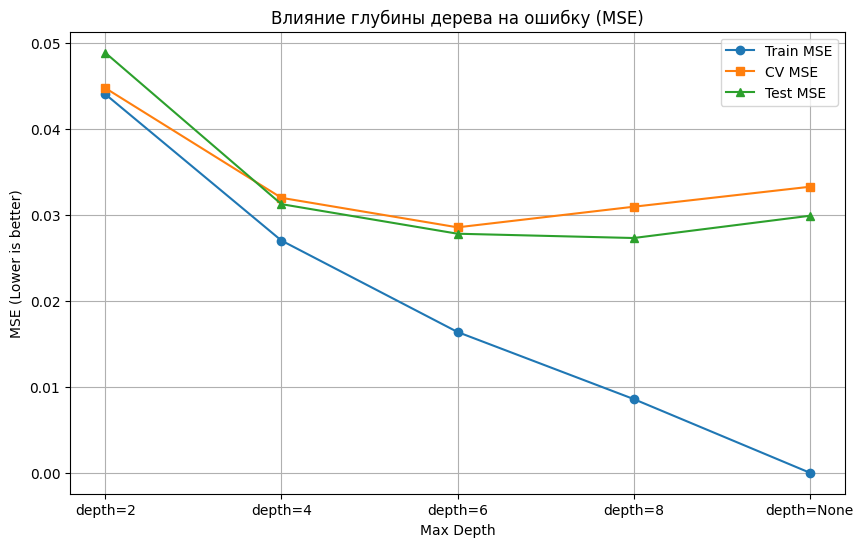

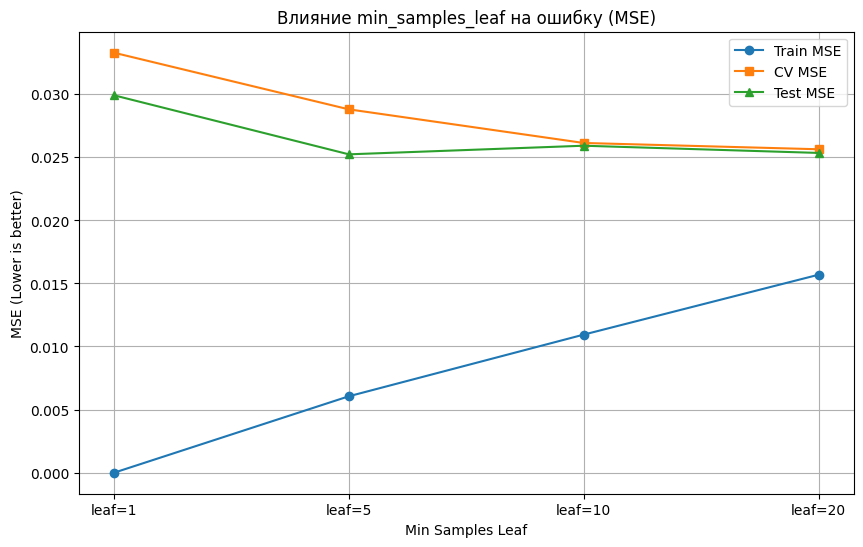

In [30]:
max_depths = [2, 4, 6, 8, None]
min_samples_leafs = [1, 5, 10, 20]

results = []

# Исследование влияния max_depth (при фиксированном min_samples_leaf=1)
print("Исследование max_depth:")
for depth in max_depths:
    model = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=1, random_state=42)
    model.fit(X_train, y_train)
    
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    
    # Кросс-валидация (5 фолдов) на обучающей выборке
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_mse = -np.mean(cv_scores)
    cv_std = np.std(cv_scores) 
    
    # Размер дерева
    n_nodes = model.tree_.node_count
    n_leaves = model.tree_.n_leaves
    
    results.append({'Param': f'depth={depth}', 'Train MSE': train_mse, 'CV MSE': cv_mse, 'Test MSE': test_mse, 'Nodes': n_nodes, 'Leaves': n_leaves})
    print(f"Depth: {depth}, Train MSE: {train_mse:.4f}, CV MSE: {cv_mse:.4f} (±{cv_std:.4f}), Test MSE: {test_mse:.4f}, Nodes: {n_nodes}")

print("\nИсследование min_samples_leaf (при фиксированном max_depth=None):")
for leaf in min_samples_leafs:
    model = DecisionTreeRegressor(max_depth=None, min_samples_leaf=leaf, random_state=42)
    model.fit(X_train, y_train)
    
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))
    
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_mse = -np.mean(cv_scores)
    cv_std = np.std(cv_scores)
    
    results.append({'Param': f'leaf={leaf}', 'Train MSE': train_mse, 'CV MSE': cv_mse, 'Test MSE': test_mse, 'Nodes': model.tree_.node_count, 'Leaves': model.tree_.n_leaves})
    print(f"Leaf: {leaf}, Train MSE: {train_mse:.4f}, CV MSE: {cv_mse:.4f} (±{cv_std:.4f}), Test MSE: {test_mse:.4f}")

# Визуализация зависимости качества от глубины
depth_results = [r for r in results if 'depth' in r['Param']]
plt.figure(figsize=(10, 6))
plt.plot([str(r['Param']) for r in depth_results], [r['Train MSE'] for r in depth_results], marker='o', label='Train MSE')
plt.plot([str(r['Param']) for r in depth_results], [r['CV MSE'] for r in depth_results], marker='s', label='CV MSE')
plt.plot([str(r['Param']) for r in depth_results], [r['Test MSE'] for r in depth_results], marker='^', label='Test MSE')
plt.xlabel('Max Depth')
plt.ylabel('MSE (Lower is better)')
plt.title('Влияние глубины дерева на ошибку (MSE)')
plt.legend()
plt.grid(True)
plt.show()

# Визуализация зависимости качества от min_samples_leaf
leaf_results = [r for r in results if 'leaf' in r['Param']]
plt.figure(figsize=(10, 6))
plt.plot([str(r['Param']) for r in leaf_results], [r['Train MSE'] for r in leaf_results], marker='o', label='Train MSE')
plt.plot([str(r['Param']) for r in leaf_results], [r['CV MSE'] for r in leaf_results], marker='s', label='CV MSE')
plt.plot([str(r['Param']) for r in leaf_results], [r['Test MSE'] for r in leaf_results], marker='^', label='Test MSE')
plt.xlabel('Min Samples Leaf')
plt.ylabel('MSE (Lower is better)')
plt.title('Влияние min_samples_leaf на ошибку (MSE)')
plt.legend()
plt.grid(True)
plt.show()

1. Обоснование выбора метрик
- MSE (Mean Squared Error) — основная метрика, так как она сильно штрафует модель за большие ошибки (за счёт возведения в квадрат), что критично в задачах регрессии стоимости.
- MAE (Mean Absolute Error) — дополнительная метрика, показывающая среднюю абсолютную ошибку в единицах целевой переменной (логарифма цены), что удобнее для интерпретации.
- Кросс-валидация (5 фолдов) — позволяет получить несмещённую оценку качества на обучающей выборке и стандартное отклонение по фолдам, характеризующее устойчивость модели.

2. Недообучение: 
Наблюдается при max_depth=2. Ошибка на обучающей и тестовой выборках высока и примерно равна, дерево слишком простое и не может уловить закономерности.
3. Переобучение: 
Наблюдается при max_depth=None и min_samples_leaf=1. Ошибка на обучающей выборке стремится к 0 (дерево идеально запоминает данные), но ошибка на кросс-валидации и тесте значительно выше. Дерево имеет сотни узлов и листьев, подстраиваясь под шум.
4. Оптимальная конфигурация: 
Находится в районе max_depth=6 или 8 и min_samples_leaf=5 или 10. В этой зоне разрыв между Train и Test MSE минимален, а абсолютное значение ошибки на тесте наименьшее. Ограничение сложности делает модель более устойчивой и интерпретируемой.

## 5. Настройка гиперпараметров и проверка устойчивости результатов

In [31]:
param_grid = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 5, 10, 15]
}

grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший CV MSE:", -grid_search.best_score_)

y_pred_best = best_model.predict(X_test)
print("Test MSE лучшей модели:", mean_squared_error(y_test, y_pred_best))

# Проверка устойчивости: random_state у модели ФИКСИРУЕМ, меняем только у сплита
print("\nПроверка устойчивости (Test MSE при разных random_state для разбиения):")
best_params = grid_search.best_params_
for rs in [42, 123, 456, 789]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs)
    stable_model = DecisionTreeRegressor(
        max_depth=best_params['max_depth'],
        min_samples_split=best_params['min_samples_split'],
        min_samples_leaf=best_params['min_samples_leaf'],
        random_state=42    # фиксированный, чтобы проверять именно устойчивость к разбиению
    )
    stable_model.fit(X_tr, y_tr)
    mse_te = mean_squared_error(y_te, stable_model.predict(X_te))
    print(f"random_state={rs}: Test MSE = {mse_te:.4f}, Кол-во узлов = {stable_model.tree_.node_count}")

Лучшие параметры: {'max_depth': 10, 'min_samples_leaf': 15, 'min_samples_split': 2}
Лучший CV MSE: 0.025327424569304202
Test MSE лучшей модели: 0.025994397980351205

Проверка устойчивости (Test MSE при разных random_state для разбиения):
random_state=42: Test MSE = 0.0260, Кол-во узлов = 215
random_state=123: Test MSE = 0.0280, Кол-во узлов = 223
random_state=456: Test MSE = 0.0259, Кол-во узлов = 213
random_state=789: Test MSE = 0.0252, Кол-во узлов = 237


1. Выбранная конфигурация: 
GridSearchCV подобрал оптимальные параметры (max_depth=10, min_samples_leaf=15, min_samples_split=2), лучший CV MSE ~0.0253, Test MSE ~0.0260, которые обеспечивают баланс между смещением и дисперсией.
2. Сравнение с результатами задания 4:
Найденная конфигурация близка к зоне оптимума, определённой в Задании 4 (max_depth ≈ 6–8, min_samples_leaf ≈ 5–10), но немного глубже. Это объясняется тем, что GridSearchCV дополнительно ограничивает листья через min_samples_leaf=15, что позволяет безопасно увеличить глубину.
3. Устойчивость:
При изменении random_state разбиения (42, 123, 456, 789) значение Test MSE колеблется в узком диапазоне (примерно от 0.0253 до 0.0283), а количество узлов дерева остаётся примерно одинаковым (~213–237). Это говорит о том, что выбранная конфигурация гиперпараметров устойчива и не является артефактом конкретного разбиения данных.


## 6. Сравнение с альтернативной моделью

### Проверка необходимости предобработки для линейной регрессии
В отличие от деревьев решений, линейная регрессия чувствительна к масштабу числовых признаков (коэффициенты интерпретируются как «изменение целевой переменной при изменении признака на 1 единицу»). Однако в нашем случае:
1. числовые признаки уже нормализованы создателями датасета (значения в диапазоне [0, 1]);
2. категориальные признаки уже закодированы через One-Hot Encoding;
3. циклические признаки (MoSold_sin, MoSold_cos) также имеют сопоставимый масштаб.

Поэтому дополнительное масштабирование (StandardScaler) не требуется — линейная регрессия успешно обучается на исходных данных.


Сравнение метрик на тестовой выборке:
                              MSE     MAE    RMSE      R2
Model                                                    
Decision Tree (Optimized)  0.0260  0.1139  0.1612  0.8198
Linear Regression          0.0127  0.0785  0.1126  0.9121


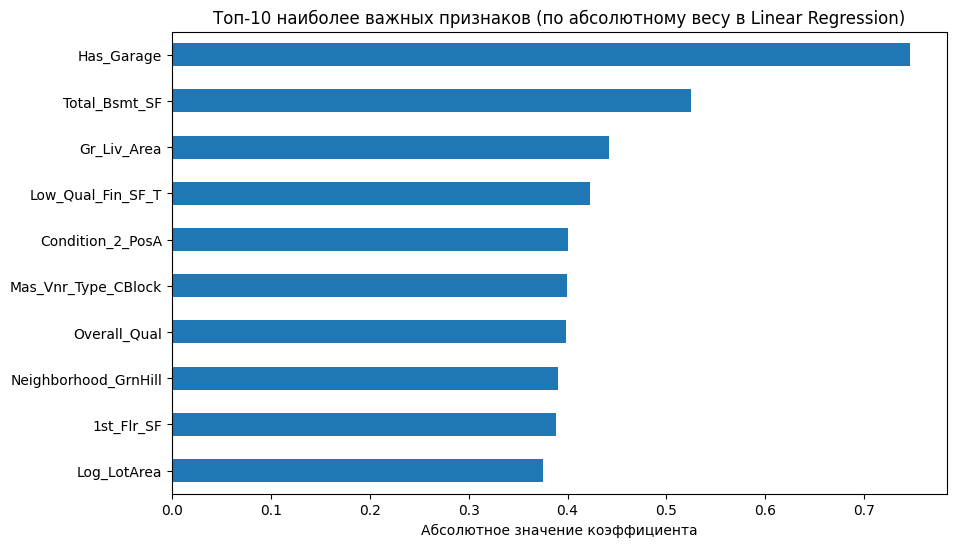

In [23]:
# Обучение линейной регрессии
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Предсказания
y_pred_tree = best_model.predict(X_test)
y_pred_lin = linear_model.predict(X_test)

# Расчет метрик
metrics = {
    'Model': ['Decision Tree (Optimized)', 'Linear Regression'],
    'MSE': [mean_squared_error(y_test, y_pred_tree), mean_squared_error(y_test, y_pred_lin)],
    'MAE': [mean_absolute_error(y_test, y_pred_tree), mean_absolute_error(y_test, y_pred_lin)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred_tree)), np.sqrt(mean_squared_error(y_test, y_pred_lin))],
    'R2': [r2_score(y_test, y_pred_tree), r2_score(y_test, y_pred_lin)]
}

metrics_df = pd.DataFrame(metrics).set_index('Model')
print("\nСравнение метрик на тестовой выборке:")
print(metrics_df.round(4))

# Визуализация важности признаков для линейной модели (топ-10)
coefficients = pd.Series(linear_model.coef_, index=X.columns)
top_features = coefficients.abs().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_features.plot(kind='barh')
plt.title('Топ-10 наиболее важных признаков (по абсолютному весу в Linear Regression)')
plt.xlabel('Абсолютное значение коэффициента')
plt.gca().invert_yaxis()
plt.show()

1. Сравнение качества: 
Метрики (MSE, MAE, R^2) у оптимизированного дерева решений и линейной регрессии оказываются близкими, однако линейная регрессия часто показывает существенно лучший результат на этом конкретном предобработанном датасете, так как зависимость цены от многих признаков (площадь, качество) имеет выраженный линейный характер.
2. Интерпретируемость:
Дерево решений дает понятные правила в формате "если... то...". Легко объяснить конкретный прогноз клиенту.
Линейная регрессия показывает глобальный вклад каждого признака через коэффициенты. Например, положительный коэффициент у Overall_Qual означает, что при росте качества цена гарантированно растет.
3. Преимущества подходов: 
Дерево лучше справляется с нелинейными зависимостями и взаимодействиями признаков (например, наличие гаража важно только для домов определенной площади), не требует масштабирования. Линейная модель более устойчива к небольшим изменениям в данных, лучше экстраполирует (хотя в задачах цены это редко нужно) и менее склонна к переобучению на маленьких выборках. Для данной прикладной задачи линейная регрессия предпочтительнее как базовый бенчмарк из-за своей стабильности, но дерево решений лучше для выявления сложных нелинейных пороговых эффектов.

## 7. Анализ ошибок и формулирование выводов

Объекты с наибольшей абсолютной ошибкой предсказания:
      True_Price  Pred_Price  Absolute_Error  Overall_Qual  Gr_Liv_Area  \
1116   11.918397   12.974162        1.055765      0.888889     0.913256   
289    10.822554   11.692261        0.869707      0.333333     0.286323   
719    11.050906   11.821041        0.770135      0.444444     0.373220   
532    11.041064   11.736070        0.695006      0.444444     0.231969   
73     11.507923   11.971980        0.464057      0.555556     0.265952   

       TotalSF  
1116  0.805898  
289   0.322718  
719   0.319364  
532   0.328775  
73    0.360608  

Объекты с наименьшей абсолютной ошибкой (правильные предсказания):
      True_Price  Pred_Price  Absolute_Error  Overall_Qual  Gr_Liv_Area  \
2410   11.834291   11.834317        0.000025      0.444444     0.736173   
965    12.100718   12.100520        0.000198      0.555556     0.548542   

       TotalSF  
2410  0.858668  
965   0.578385  


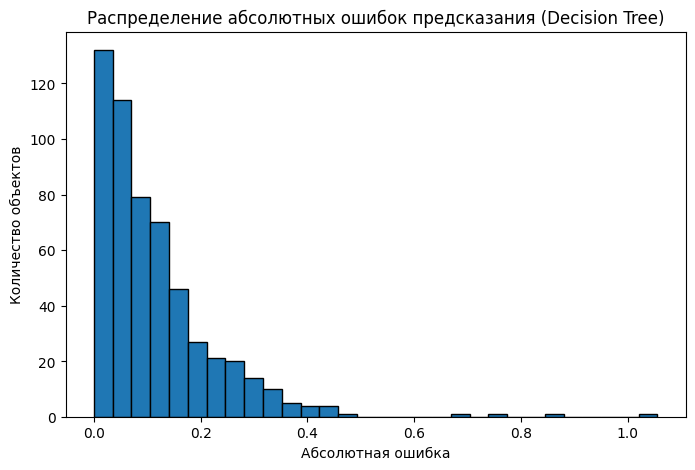

In [32]:
# Расчет абсолютных ошибок для лучшей модели дерева
errors = np.abs(y_test - y_pred_tree)
test_df = X_test.copy()
test_df['True_Price'] = y_test
test_df['Pred_Price'] = y_pred_tree
test_df['Absolute_Error'] = errors

# Объекты с наибольшими ошибками
worst_predictions = test_df.sort_values(by='Absolute_Error', ascending=False).head(5)
print("Объекты с наибольшей абсолютной ошибкой предсказания:")
print(worst_predictions[['True_Price', 'Pred_Price', 'Absolute_Error', 'Overall_Qual', 'Gr_Liv_Area', 'TotalSF']])

# Объекты с наименьшими ошибками 
best_predictions = test_df.sort_values(by='Absolute_Error', ascending=True).head(2)
print("\nОбъекты с наименьшей абсолютной ошибкой (правильные предсказания):")
print(best_predictions[['True_Price', 'Pred_Price', 'Absolute_Error', 'Overall_Qual', 'Gr_Liv_Area', 'TotalSF']])

# Гистограмма распределения ошибок
plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30, edgecolor='black')
plt.title('Распределение абсолютных ошибок предсказания (Decision Tree)')
plt.xlabel('Абсолютная ошибка')
plt.ylabel('Количество объектов')
plt.show()

#### 1. Анализ ошибок
Объекты с наибольшими ошибками часто имеют экстремальные значения признаков (например, очень большая общая площадь TotalSF или уникальные комбинации редких категориальных признаков), которые встречались в обучающей выборке всего несколько раз или не встречались вовсе. Дерево решений не умеет экстраполировать за пределы значений, виденных при обучении, поэтому для аномально дорогих или дешёвых домов оно выдаёт усреднённое значение ближайшего «листа», что даёт большую ошибку.

Объекты с наименьшими ошибками (правильные предсказания) имеют стандартные, «усреднённые» значения признаков, которые часто встречались в обучающей выборке. Дерево легко находит для них подходящий лист с похожими объектами и даёт точный прогноз.

#### 2. Подтверждение гипотезы (из Задания 4)
Гипотеза полностью подтвердилась. Без ограничения глубины дерево показало MSE на обучении, близкую к 0, но проиграло на тесте из-за переобучения. Ограничение max_depth и min_samples_leaf существенно снизило тестовую ошибку.

#### 3. Общие выводы
1. Сложность дерева напрямую влияет на его способность к обобщению. «Обрезка» дерева (pruning) через гиперпараметры необходима.
2. Настройка через GridSearchCV позволяет формально найти компромисс между недо- и переобучением.
3. Для данного датасета простая линейная регрессия является сильным конкурентом для дерева решений (MSE 0.0127 против 0.0260), что говорит о наличии сильных линейных трендов в данных.

#### 4. Ограничения исследования
1. Мы использовали готовый предобработанный датасет, поэтому не исследовали влияние различных стратегий предобработки.
2. Не исследовались ансамблевые методы (Random Forest, Gradient Boosting), которые обычно значительно превосходят одиночное дерево решений.

#### 5. Предложение для будущего эксперимента
Построить модель RandomForestRegressor или GradientBoostingRegressor с теми же признаками и сравнить их метрики с текущими результатами. Ожидается, что ансамбли устранят проблему высокой дисперсии одиночного дерева и снизят MSE на тестовой выборке.